In [1]:
%pip install matplotlib seaborn
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1) Import all required libraries

In [2]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

## 1.1 Converting Excel sheet to database files 

In [3]:
excel_file = pd.ExcelFile("customer_churn_dataset.xlsx")

customer = pd.read_excel(excel_file, sheet_name="db_customer")
subscription = pd.read_excel(excel_file, sheet_name="db_subscription")
support = pd.read_excel(excel_file, sheet_name="db_support")

In [5]:
# Create database connection
conn = sqlite3.connect('customer_churn_10000.db')

# Convert DataFrames into SQL tables
customer.to_sql('db_customer', conn, if_exists='replace', index=False)
subscription.to_sql('db_subscription', conn, if_exists='replace', index=False)
support.to_sql('db_support', conn, if_exists='replace', index=False)

conn.close()

### 2) Connect your database with python using sqlite3 connection 

In [3]:
# import database from sql db

In [7]:
# Create database connection
conn = sqlite3.connect('customer_churn_10000.db')

sql_query = """
    select name 
    from sqlite_master
    where type='table'
"""

tables = pd.read_sql(sql_query, conn)

#create dataframes for each table in db 
for table_name in tables['name']:
    df = pd.read_sql(f"Select * from {table_name}", conn)
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")

conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


# Working on database one by  and cleaning 

### 1) Db_Customer

In [8]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [9]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [10]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


### 3) Data Cleaning for each dataframe 

In [11]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  10000 non-null  str   
 1   name        10000 non-null  str   
 2   country     9731 non-null   str   
 3   state       10000 non-null  str   
 4   gender      10000 non-null  str   
 5   dob         10000 non-null  str   
 6   interests   2189 non-null   str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 625.1+ KB


In [12]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [13]:
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
9995,19974-WCXCP,raju,India,Maharashtra,Female,1990-02-19 00:00:00,NaN,None
9996,19975-NBXVC,mohan,India,Nagaland,Women,1977-03-22 00:00:00,NaN,None
9997,19976-WAGVV,rishabh,India,Delhi,Female,1966-02-05 00:00:00,drama,None
9998,19977-UWFZT,madan,India,Maharashtra,Women,1981-02-02 00:00:00,NaN,None
9999,19978-OTBXA,mina,India,Karnataka,Men,1989-05-22 00:00:00,NaN,None


### According to the info each column should have 21 entries if its less than 21 then the column has missing values 

#### 1) Rename columns - name to customer_name

#### 2) Drop the columns which are not in use 
#### --> for ex: pincode has 0 values its of no use remove it, intrests is of no use it has only 4 values 

#### 3) DOB has a datatype of Object convert it into datetime 

#### 4) Data Standardisation of gender column some them are female and some of them are written as Women 

#### 5) Fix missing values in Countries


### 1) Rename columns - name to customer_name

In [14]:
df_db_customer.rename(columns={'name':'customer_name'}, inplace=True) #inplace=True means make changes directly to the original DataFrame instead of creating a new DataFrame.

C:\Users\hp\AppData\Local\Temp\ipykernel_4780\2042911963.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_db_customer.rename(columns={'name':'customer_name'}, inplace=True) #inplace=True means make changes directly to the original DataFrame instead of creating a new DataFrame.


### 2) Drop the columns which are not in use - intrests and pincode

In [15]:
df_db_customer.columns[-2:]

Index(['interests', 'pincode'], dtype='str')

In [16]:
df_db_customer.drop(df_db_customer.columns[-2:], axis=1, inplace=True) # axis lets you select whether you want to delete a whole column or whole row of intrest or pincode  axis = 1-> columns and axis = 0 -> rows
#df_db_customer.drop(columns=['intrests','pincode'], inlace=true) --> you can use direct names of columns to delete them 

C:\Users\hp\AppData\Local\Temp\ipykernel_4780\782130533.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_db_customer.drop(df_db_customer.columns[-2:], axis=1, inplace=True) # axis lets you select whether you want to delete a whole column or whole row of intrest or pincode  axis = 1-> columns and axis = 0 -> rows


In [17]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
...,...,...,...,...,...,...
9995,19974-WCXCP,raju,India,Maharashtra,Female,1990-02-19 00:00:00
9996,19975-NBXVC,mohan,India,Nagaland,Women,1977-03-22 00:00:00
9997,19976-WAGVV,rishabh,India,Delhi,Female,1966-02-05 00:00:00
9998,19977-UWFZT,madan,India,Maharashtra,Women,1981-02-02 00:00:00


### 3) DOB has a datatype of Object convert it into datetime

In [18]:
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [19]:
df_db_customer['dob']

0      1982-04-12
1      1995-11-23
2      1978-02-15
3      2001-08-30
4      1990-05-05
          ...    
9995   1990-02-19
9996   1977-03-22
9997   1966-02-05
9998   1981-02-02
9999   1989-05-22
Name: dob, Length: 10000, dtype: datetime64[us]

In [20]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     10000 non-null  str           
 1   customer_name  10000 non-null  str           
 2   country        9731 non-null   str           
 3   state          10000 non-null  str           
 4   gender         10000 non-null  str           
 5   dob            10000 non-null  datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 468.9 KB


### 4) Data Standardisation of gender column some them are female and some of them are written as Women

In [21]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female', 'Women', 'Men']
Length: 4, dtype: str

In [22]:
# Convert all Men --> Male and Women --> Female

In [23]:
df_db_customer['gender']=df_db_customer['gender'].replace({'Men': 'Male', 'Women':'Female'},inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_4780\380555743.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/docs/dev/user_guide/migration.html#copy-on-write-cow
  df_db_customer['gender']=df_db_customer['gender'].replace({'Men': 'Male', 'Women':'Female'},inplace=True)


In [24]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [25]:
df_db_customer['gender']

0         Male
1         Male
2       Female
3         Male
4       Female
         ...  
9995    Female
9996    Female
9997    Female
9998    Female
9999      Male
Name: gender, Length: 10000, dtype: str

### 5) Fix missing values in Countries

In [26]:
df_db_customer['country'].isna() # isna()-> provides you the null values in column in boolean form True=null values

0       False
1       False
2       False
3       False
4       False
        ...  
9995    False
9996    False
9997    False
9998    False
9999    False
Name: country, Length: 10000, dtype: bool

In [27]:
df_db_customer[df_db_customer['country'].isna()] # gives you the values which are null values in country 

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01
35,10014-FYWIR,raghvendra,NaN,Maharashtra,Male,1991-02-23
59,10038-KHGYL,durga,NaN,Uttar Pradesh,Male,1983-05-17
...,...,...,...,...,...,...
9883,19862-KVNEE,raghvendra,NaN,Nagaland,Male,1972-08-24
9889,19868-FTYTV,shiva,NaN,Kathmandu,Female,1975-08-12
9894,19873-MDBFJ,rangadevi,NaN,Meghalaya,Male,1965-03-25
9942,19921-VAACL,maya,NaN,Telangana,Female,1992-03-23


In [28]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
...,...,...
9995,India,Maharashtra
9996,India,Nagaland
9997,India,Delhi
9998,India,Maharashtra


In [29]:
  # country and state - unique value pair 
state_country_mapping = (
    df_db_customer
    .dropna(subset=['country'])  # Remove rows where country is missing
    .set_index('state')['country']  # Set state as index and select country column
    .to_dict()  # Convert the Series into a Python dictionary
)

df_db_customer['country']= df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [30]:
df_db_customer[df_db_customer['country'].isna()] 

,customerid,customer_name,country,state,gender,dob


### 2) Db_subscription

In [31]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [32]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               10000 non-null  str    
 1   subscription_start_date  10000 non-null  str    
 2   subscription_type        10000 non-null  str    
 3   renewal_date             10000 non-null  str    
 4   plan_type                10000 non-null  str    
 5   contract_type            10000 non-null  str    
 6   cancellation_date        1881 non-null   str    
 7   cancellation_reason      1881 non-null   str    
 8   monthly_charges          10000 non-null  float64
 9   cltv                     10000 non-null  int64  
 10  churn_score              10000 non-null  int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 859.5 KB


### In this data base there no major changes in the columns the only change is we need to change the all date time column which has datatype in str into datetime datatype and other str into objects

In [33]:
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col]= df_db_subscription[date_col].apply(pd.to_datetime)

In [34]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               10000 non-null  str           
 1   subscription_start_date  10000 non-null  datetime64[us]
 2   subscription_type        10000 non-null  str           
 3   renewal_date             10000 non-null  datetime64[us]
 4   plan_type                10000 non-null  str           
 5   contract_type            10000 non-null  str           
 6   cancellation_date        1881 non-null   datetime64[us]
 7   cancellation_reason      1881 non-null   str           
 8   monthly_charges          10000 non-null  float64       
 9   cltv                     10000 non-null  int64         
 10  churn_score              10000 non-null  int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 859.5 KB


In [35]:
str_columns = df_db_subscription.select_dtypes(include=['str']).columns #### as we can see most of the columns have string as a datatype which can affect the final result.
df_db_subscription[str_columns] = df_db_subscription[str_columns].astype('object') ## so here we are directly choosing the columns we str data type and changing them into object 

In [36]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               10000 non-null  object        
 1   subscription_start_date  10000 non-null  datetime64[us]
 2   subscription_type        10000 non-null  object        
 3   renewal_date             10000 non-null  datetime64[us]
 4   plan_type                10000 non-null  object        
 5   contract_type            10000 non-null  object        
 6   cancellation_date        1881 non-null   datetime64[us]
 7   cancellation_reason      1881 non-null   object        
 8   monthly_charges          10000 non-null  float64       
 9   cltv                     10000 non-null  int64         
 10  churn_score              10000 non-null  int64         
dtypes: datetime64[us](3), float64(1), int64(2), object(5)
memory usage: 859.5+ KB


### 3) Db_Support

In [37]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [38]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      200 non-null    str   
 1   complaint_date  200 non-null    str   
 2   escalations     200 non-null    str   
 3   csat_score      200 non-null    int64 
 4   col_1           0 non-null      object
 5   comment         146 non-null    str   
dtypes: int64(1), object(1), str(4)
memory usage: 9.5+ KB


### In this database according to the info displayed there is a garbage columns i.e col_1 and comment we need to drop both of them as they are no use of our data analysis.

In [39]:
df_db_support.columns[-2:]

Index(['col_1', 'comment'], dtype='str')

In [40]:
df_db_support.drop(df_db_support.columns[-2:], axis=1, inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_4780\3655798878.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_db_support.drop(df_db_support.columns[-2:], axis=1, inplace=True)


In [41]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customerid      200 non-null    str  
 1   complaint_date  200 non-null    str  
 2   escalations     200 non-null    str  
 3   csat_score      200 non-null    int64
dtypes: int64(1), str(3)
memory usage: 6.4 KB


In [42]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [43]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      200 non-null    str           
 1   complaint_date  200 non-null    datetime64[us]
 2   escalations     200 non-null    str           
 3   csat_score      200 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 6.4 KB


# Feature Engineering and data analysis

### In our subscription database there is proper indication if the customer has been churned or not so lets create a churn_flag for it 

In [44]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


#### As we can see in data people have cancellad their subscription plan and we have dates for the same to create a flag we will use cancellation_date 
#### so if cancellation_Date is present = 1 and if if cancellation_Date is absent = 0


In [45]:
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)

In [46]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


## mergeing support and customer database wiht main subscription database 

In [47]:
df = ( df_db_subscription
    .merge(df_db_customer, on = 'customerid', how = 'left')
    .merge(df_db_support, on = 'customerid', how= 'left') )

In [48]:
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,N,60.0
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9997,19974-WCXCP,2021-05-16,Refferal,2026-05-16,Basic,Monthly,NaT,NaN,8.99,40,26,0,raju,India,Maharashtra,Female,1990-02-19,NaT,NaN,NaN
9998,19975-NBXVC,2022-08-11,Paid,2026-08-11,Basic,Monthly,NaT,NaN,8.99,1109,13,0,mohan,India,Nagaland,Female,1977-03-22,NaT,NaN,NaN
9999,19976-WAGVV,2020-03-18,Refferal,2024-03-18,Standard,Annual,NaT,NaN,13.99,130,43,0,rishabh,India,Delhi,Female,1966-02-05,NaT,NaN,NaN
10000,19977-UWFZT,2020-02-01,Organic,2021-02-01,Premium,Monthly,2020-04-07,Not enough content,92.99,40,75,1,madan,India,Maharashtra,Female,1981-02-02,NaT,NaN,NaN


In [49]:
df.shape

(10002, 20)

In [50]:
df_db_subscription.shape

(10000, 12)

In [51]:
df_db_support.shape

(200, 4)

### Now if you see the shape value its showing there are total 23 rows in  but in subscription database we have only 21 rows means 2 of the records have been duplicated 

In [52]:
print('df_db_subscription unique value:', df_db_subscription['customerid'].nunique())
print('df_db_customer unique value:', df_db_customer['customerid'].nunique())
print('df_db_support unique value:', df_db_support['customerid'].nunique())
print('df_db_support all value:', df_db_support['customerid'].size)

df_db_subscription unique value: 10000
df_db_customer unique value: 10000
df_db_support unique value: 198
df_db_support all value: 200


### Here we found a bug in support table we got a unique values as 7 but we see the total size of support table it shows total rows 9 means in this table 2 rows are been copied or duplicated due to which our count is showing 23 instead of 21 

In [53]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
...,...,...,...,...
195,19978-OTBXA,2024-06-29,N,90
196,17974-POXVR,2025-03-03,Y,8
197,10476-SFTVB,2024-08-08,N,84
198,10319-DHNNE,2025-09-21,N,56


In [54]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count') ## grouping the values based on the customer id and counting the grouped values 

In [55]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
0,0003-MKNFE,2024-08-28,N,60,2
1,0003-MKNFE,2024-08-28,Y,10,2
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
...,...,...,...,...,...
195,19978-OTBXA,2024-06-29,N,90,1
196,17974-POXVR,2025-03-03,Y,8,1
197,10476-SFTVB,2024-08-08,N,84,1
198,10319-DHNNE,2025-09-21,N,56,1


In [56]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep='last') ## dropping the duplicate values based on the count and keeping the last updated value based on the sorted date 

In [57]:
df_db_support['customerid'].size

198

In [58]:
#### again merging after removing duplicates 
# merge df
df = (df_db_subscription
.merge(df_db_customer, on = 'customerid', how= 'left')
.merge(df_db_support, on = 'customerid', how= 'left') )

In [59]:
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,0,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,NaN
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,1,mira,India,Delhi,Female,1990-05-05,2024-01-20,Y,20.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,19974-WCXCP,2021-05-16,Refferal,2026-05-16,Basic,Monthly,NaT,NaN,8.99,40,...,0,raju,India,Maharashtra,Female,1990-02-19,NaT,NaN,NaN,NaN
9996,19975-NBXVC,2022-08-11,Paid,2026-08-11,Basic,Monthly,NaT,NaN,8.99,1109,...,0,mohan,India,Nagaland,Female,1977-03-22,NaT,NaN,NaN,NaN
9997,19976-WAGVV,2020-03-18,Refferal,2024-03-18,Standard,Annual,NaT,NaN,13.99,130,...,0,rishabh,India,Delhi,Female,1966-02-05,NaT,NaN,NaN,NaN
9998,19977-UWFZT,2020-02-01,Organic,2021-02-01,Premium,Monthly,2020-04-07,Not enough content,92.99,40,...,1,madan,India,Maharashtra,Female,1981-02-02,NaT,NaN,NaN,NaN


In [60]:
df.shape

(10000, 21)

### Export dataframe into csv file for better Data analysis purpose

In [67]:
# export dataframe to csv file
df.to_csv('exported_churn_data.csv', index=False)

# Data Analysis on our exported final dataset

## 1. Calculating the churn rate 
### Churn rate = churned customer / total customers

In [68]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [69]:
## 1. Churn Rate
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = " , round(churn_rate,2), "%")

Churn Rate =  18.81 %


## 2. Calculating the Retention rate

In [70]:
## 2. Retention Rate 
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), "%")


Retention Rate =  81.19 %


## 3. Calculating the Churn by Plan type 

In [71]:
## 3. Churn by Plan type
churn_by_plan = df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index()

In [72]:
churn_by_plan

,plan_type,churn_flag
0,Basic,18.78
1,Premium,18.56
2,Standard,19.02


## 4(a). Calculating the churn by state and the total revenue generated by each state 

In [73]:
churn_by_state = df.groupby('state').agg(
    churn_rate = ('churn_flag', lambda x: x.mean() * 100),
    total_revenue = ('monthly_charges', 'sum'),
    total_users = ('customerid', 'nunique')
).round(2).reset_index()

In [74]:
churn_by_state

,state,churn_rate,total_revenue,total_users
0,Delhi,20.71,26598.33,1067
1,Karnataka,20.03,28430.17,1183
2,Kathmandu,16.94,26099.61,1139
3,Maharashtra,19.12,27536.81,1119
4,Meghalaya,19.27,24329.36,1064
5,Nagaland,18.35,24937.88,1112
6,Rajasthan,17.02,25858.25,1075
7,Telangana,19.56,26191.16,1084
8,Uttar Pradesh,18.32,26988.43,1157


## 4(b). Churn by Subscription Type + Sum of Revenue & Count of Users

In [75]:
churn_by_subscription =  df.groupby('subscription_type').agg(
    churn_rate = ('churn_flag', lambda x: x.mean() * 100),
    total_revenue = ('monthly_charges', 'sum'),
    total_users = ('customerid', 'nunique')
).round(2).reset_index()

In [76]:
churn_by_subscription

,subscription_type,churn_rate,total_revenue,total_users
0,Organic,19.22,100008.76,4224
1,Paid,18.40,70300.66,2934
2,Refferal,18.61,66660.58,2842


## 5. ARPU - Avg Revenue per user

In [77]:
#5 Avg revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ', round(arpu,2))


ARPU =  23.7


## 6. Avg Customer Tenure


In [78]:
## count of days users has used our service to cancellation date else current date
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
        df['cancellation_date'].notna(), # condition 

        (df['cancellation_date'] - df['subscription_start_date']).dt.days, # if above condition is true - cancellation date is not null 

        (today - df['subscription_start_date']).dt.days # if above condition is false - cancellation date is null

)

# now we want avg tenure so we will take mean 
avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Days) = ", round(avg_tenure),0)


Avg Tenure (Days) =  1723 0


## 7. Revenue at risk - revenue lost from churned users


In [79]:
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs 'K') =", revenue_at_risk)


Revenue at Risk (Rs 'K') = 44805.19


## 8. Escalation Rate

In [80]:
escalation_rate = (df['escalations']=='Y').mean()*100 # escalation means when your complain is not resloved and then the topic is escalated and taken at the bigger level
print("Esclation Rate = ", round(escalation_rate, 2), "%")

Esclation Rate =  0.79 %


## 9. Avg Complaint Per User


In [81]:
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Compliants Per User = ", round(avg_complaints, 2))


Avg Compliants Per User =  0.02


## 10. Correlation Esclation vs Churn

In [82]:
## people who are escalating are leaving the platform this is what we are calculating 
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) ## encoded escalation column Y to 1 or 0 i.e from string to int 
corr_df = df[['escalations', 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(corr_df['churn_flag'])
print("Correlation between esclation vs churn is = ", round(correlation,2))


Correlation between esclation vs churn is =  0.01


In [83]:
df['escalations'] 

0       0
1       1
2       0
3       0
4       1
       ..
9995    0
9996    0
9997    0
9998    0
9999    0
Name: escalations, Length: 10000, dtype: int64

## 11. Create a column using existing col - Churn risk


In [84]:
# 11. Create a column using existing col - Churn risk
conditions = [
 (df['churn_score'] < 50),
 (df['churn_score'] >= 50) & (df['churn_score'] < 70),
 (df['churn_score'] >= 70)
]
choices = ['low', 'med', 'high']
df['churn_risk'] = np.select(conditions, choices, default='unkown')


In [85]:
df['churn_risk']

0        low
1       high
2        low
3        low
4       high
        ... 
9995     low
9996     low
9997     low
9998    high
9999     low
Name: churn_risk, Length: 10000, dtype: str

# Visualization using Matplotlib

In [86]:
# best practice to create a copy then work on it
df_visual = df.copy()

In [87]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk'],
      dtype='str')

## 4.1 Monthly Churn Trend (Time Series KPI)

In [88]:
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

In [89]:
df_visual['cancellation_month'] 

0           NaT
1       2024-09
2           NaT
3           NaT
4       2024-02
         ...   
9995        NaT
9996        NaT
9997        NaT
9998    2020-04
9999        NaT
Name: cancellation_month, Length: 10000, dtype: period[M]

In [90]:
churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

In [91]:
churn_trend

cancellation_month
2019-03     1
2019-04     7
2019-06     4
2019-07     3
2019-08     3
           ..
2025-08    20
2025-09    24
2025-10    22
2025-11    32
2025-12    23
Freq: M, Length: 81, dtype: int64

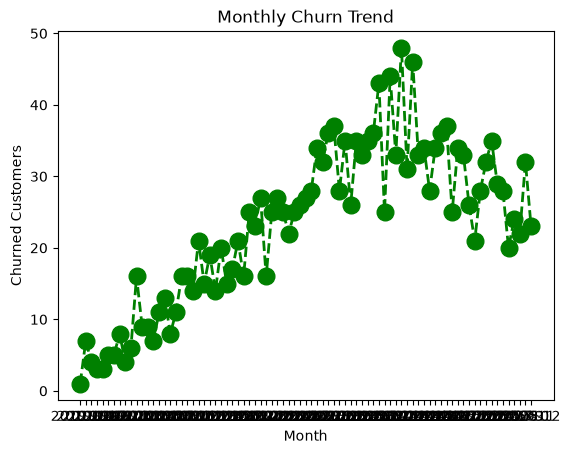

In [92]:
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2, markersize=12)
plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

## 4.2 Churn rate by Plan type

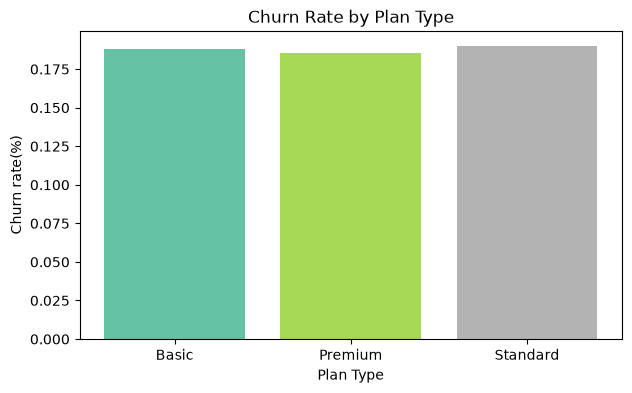

In [95]:
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

colors = plt.cm.Set2(np.linspace(0,1,len(churn_plan)))

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel("Churn rate(%)")
plt.show()

## 4.3 Churn by States

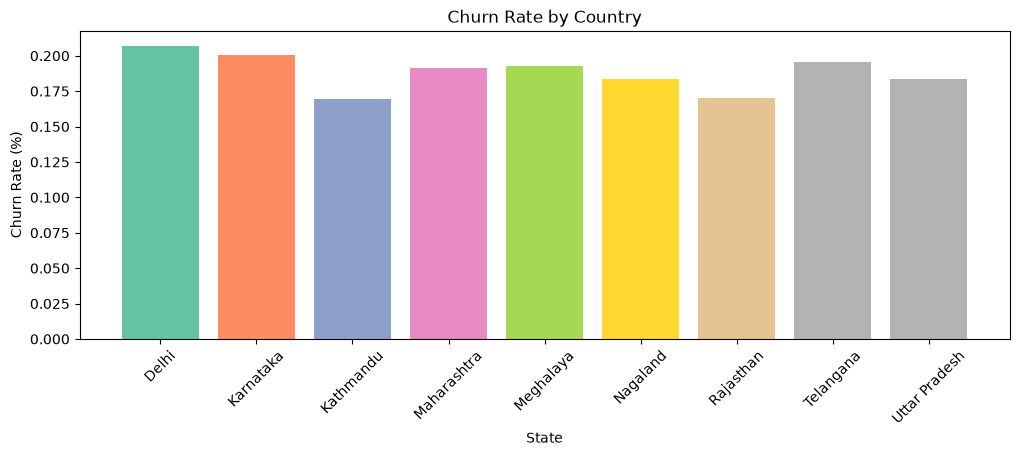

In [96]:
churn_plan = df_visual.groupby('state')['churn_flag'].mean()


# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Country')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

# Visulaization using Seaborn

## Heatmap (Correlation Matrix)

In [97]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [98]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [99]:
# remove warnings
import warnings
warnings.filterwarnings("ignore")

In [100]:
# incorrect method of encoding - as numbers are not assigned based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

<Axes: >

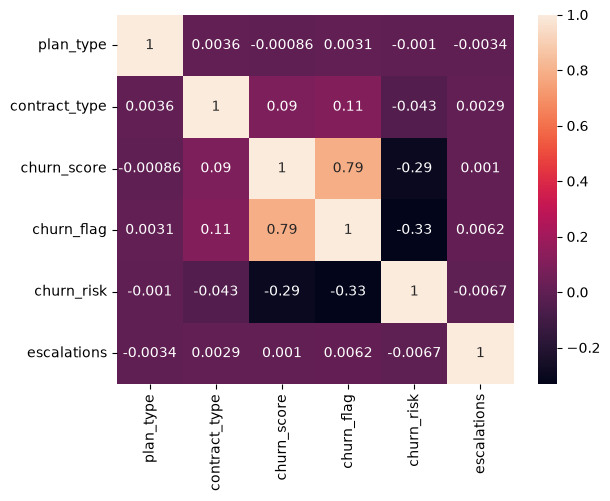

In [101]:
# Heatmap (correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

In [102]:
print('plan_type :', df_visual['plan_type'].unique())
print('contract_type :', df_visual['contract_type'].unique())
print('churn_risk :', df_visual['churn_risk'].unique())

plan_type : ['Standard' 'Premium' 'Basic']
contract_type : ['Annual' 'Monthly']
churn_risk : <StringArray>
['low', 'high', 'med']
Length: 3, dtype: str


In [103]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [104]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [105]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

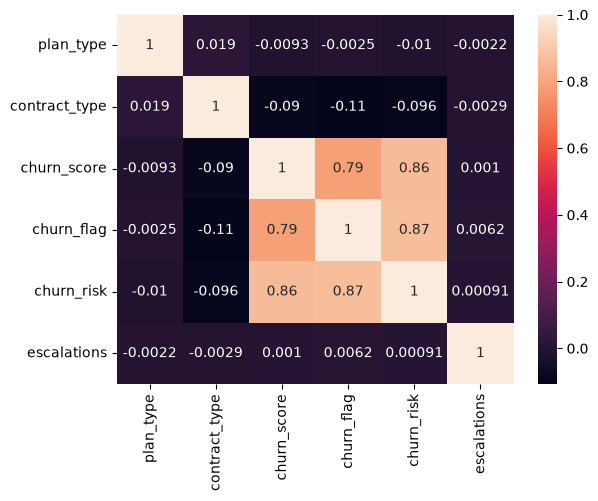

In [106]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

## pairplot - Plot pairwise relationships in a dataset

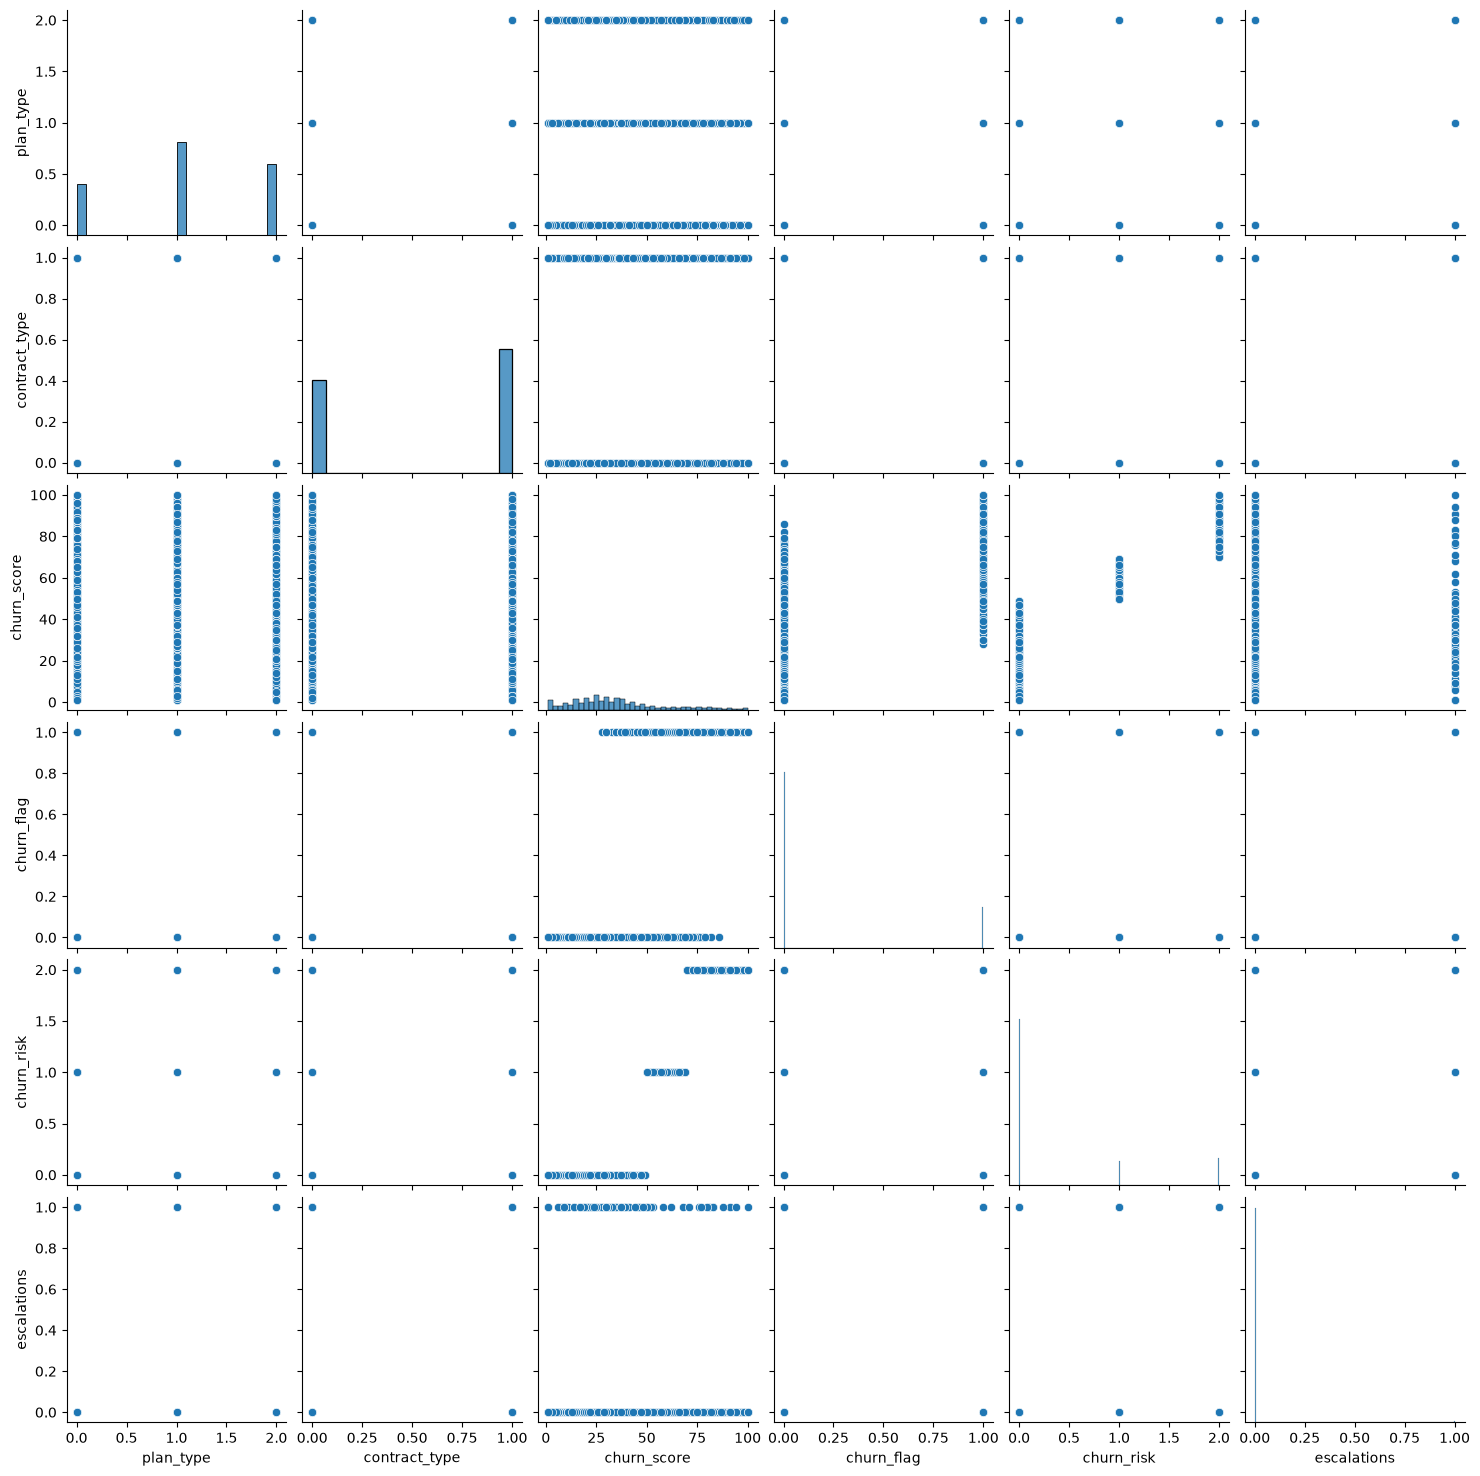

In [107]:
sns.pairplot(df_encoded)

## catplt/Facegrid plot - multi-dim comparison

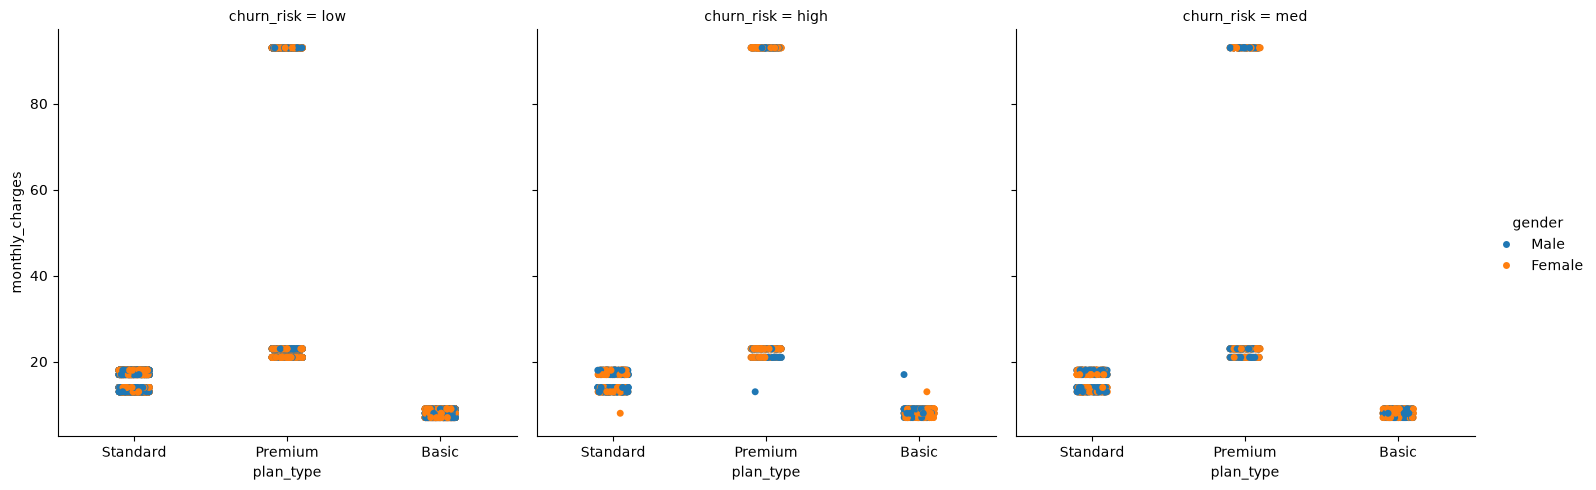

In [108]:
sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')